# Capture: constant, changing, and driven

**Working notebook and code by Codex (OpenAI), 2026-10-25.** Capture is dr. kraemer's proposed quantity; the starting table and terminology came through Claude. These are model-written working notes, not book text.

Start with a shaft whose capture is steady. Then let capture change as the shaft turns. Watch which shortcuts fail—and which physical balances keep working. The last experiment adds damping and an independent periodic torque drive, giving a nonlinear ring a route to chaotic motion.

**SI is the default.** Every live panel has a unit selector. Open *Units* to choose other units without changing the apparatus. Explicit book units can also be selected in the code. Static figures below remain readable without a running kernel; the final cell connects the live controls.

Keep this notebook beside `capture_behavior.py`, `behavior_panel.py`, and `display_units.py`. It needs NumPy, SciPy, Matplotlib, IPython, and ipywidgets; this notebook does not require Manim.

In [1]:
import numpy as np
from IPython.display import display
from capture_behavior import CaptureLaw, prescribed, charge_pulse, driven
from behavior_panel import plot_prescribed, plot_pulses, plot_driven, explore_behavior

# Omit this dictionary for SI defaults. To opt into book units, for example:
# DISPLAY_UNITS = {"angle": "stroke", "spin": "roll", "energy": "thump"}
DISPLAY_UNITS = {}
constant = CaptureLaw('constant', base=0.5)
rippled = CaptureLaw('ripple', base=0.5, ripple=0.8)
ring = CaptureLaw('ring', base=1.0)

## 1. Turn the shaft yourself

A drive prescribes the shaft's motion; it supplies whatever torque is needed to do so. The angle starts at 0.3 rad, the sweep at 1 rad/s, and the pickup is 0.2 rad/s². Compare linkage, capture, voltage, and the voltage's climb.

With **constant capture, 0.5 Wb/rad**, a straight line predicts the linkage. The voltage's climb is simply the capture of the pickup. The red full result and the blue shortcut lie on top of one another.

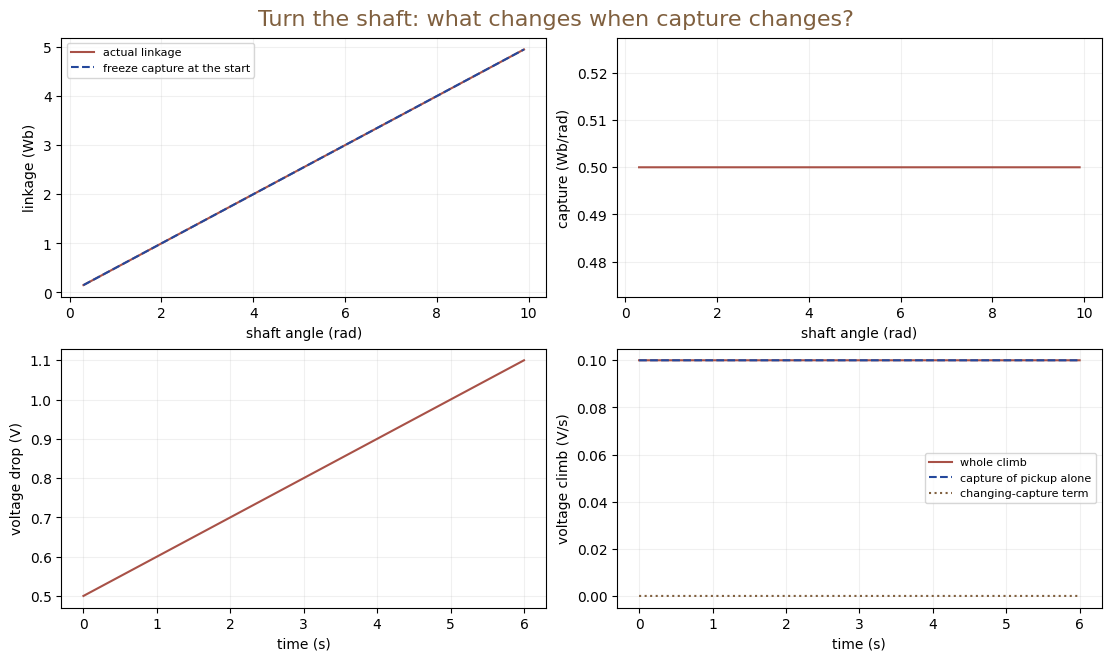

In [2]:
_ = plot_prescribed(constant)

Now use $\kappa(\theta)=0.5[1+0.8\cos\theta]$ Wb/rad. This is a smooth model of an effective motor coupling that ripples with shaft angle. The constant-capture case is an ideal commutated reference; neither effective model describes flux accumulating forever in one unswitched coil.

The instantaneous relationships still hold:

$$d\lambda=\kappa\,d\theta,\qquad \chi=\kappa i,\qquad \mathcal E=\kappa\omega.$$

Here $\mathcal E$ is the signed **voltage drop** used in the motor's terminal balance. The generated EMF around positive current is its opposite.

But a frozen capture no longer predicts the whole linkage change. And the voltage's climb is

$$\dot{\mathcal E}=\kappa\dot\omega+\dot\kappa\omega
=\kappa\dot\omega+\frac{d\kappa}{d\theta}\omega^2.$$

The brown curve below is the extra term. Even at constant sweep, a changing capture can make the voltage climb and fall. This is regular variation, not chaos.

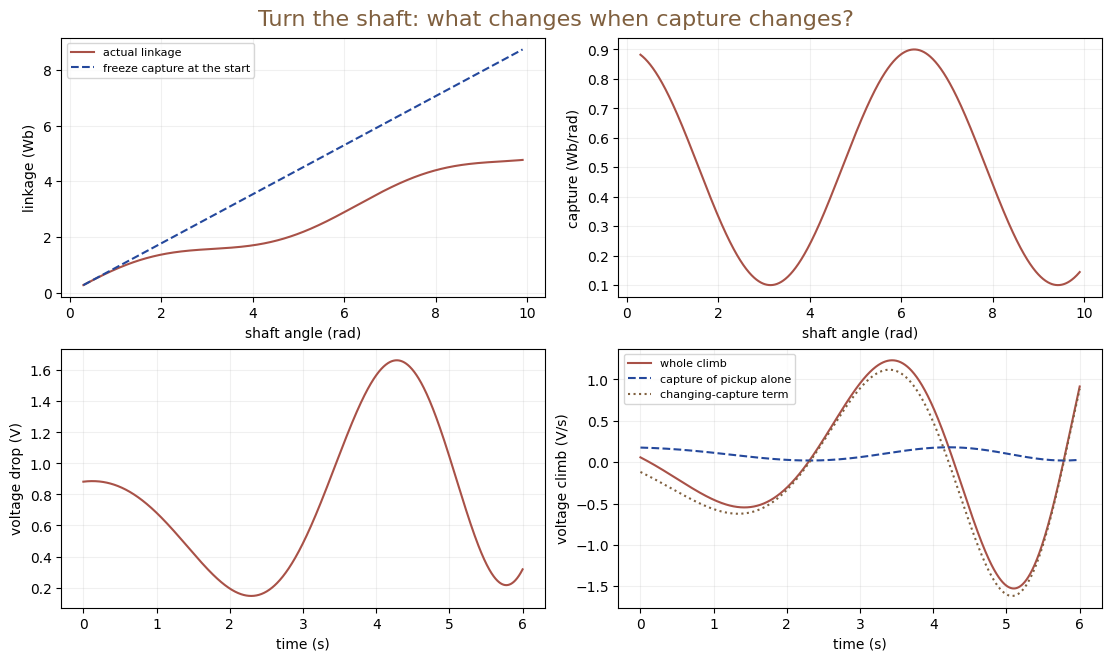

In [3]:
_ = plot_prescribed(rippled)

## 2. Same charge, early or late

A free shaft starts at 0.3 rad and 1 rad/s, with inertia 0.1 kg·m². An ideal current source sends a smooth **0.2 C** pulse through the winding, lasting 0.3 s. Compare a pulse centered at 0.5 s with an otherwise identical pulse centered at 2.5 s. There is no external shaft torque or friction in this experiment. The current source supplies the required voltage; its work can differ between the two motions.

Constant capture gives

$$\Delta L=\int\chi\,dt=\int\kappa\,dQ=\kappa Q.$$

Both pulses therefore add **0.1 N·m·s**, although the early pulse lets the shaft turn farther before the experiment ends. The diagonal plot is a direct test of *the capture of charge is spin added*.

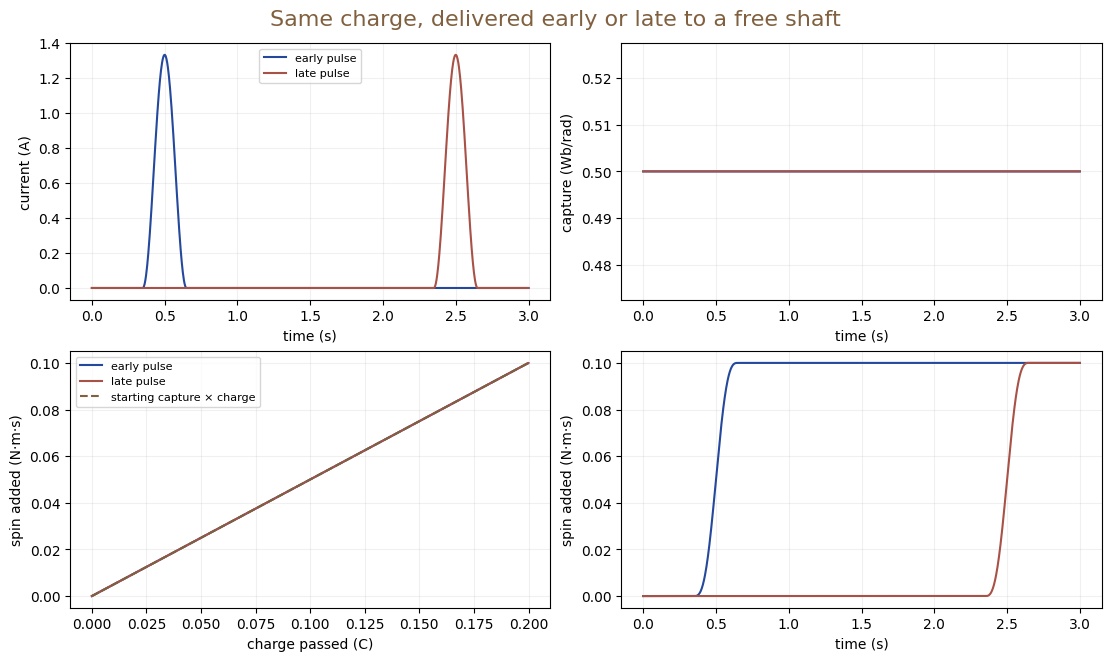

In [4]:
_ = plot_pulses(constant)

With changing capture, charge delivered at different shaft positions has different leverage on the spin:

$$\Delta L=\int\kappa(\theta(t))\,dQ.$$

Both sources still pass 0.2 C. With the rippled coupling below the early pulse adds about **0.15 N·m·s**, while the late pulse adds about **0.025 N·m·s**. The shortcut using starting capture misses both. In either run, work on the shaft still equals its change in kinetic energy.

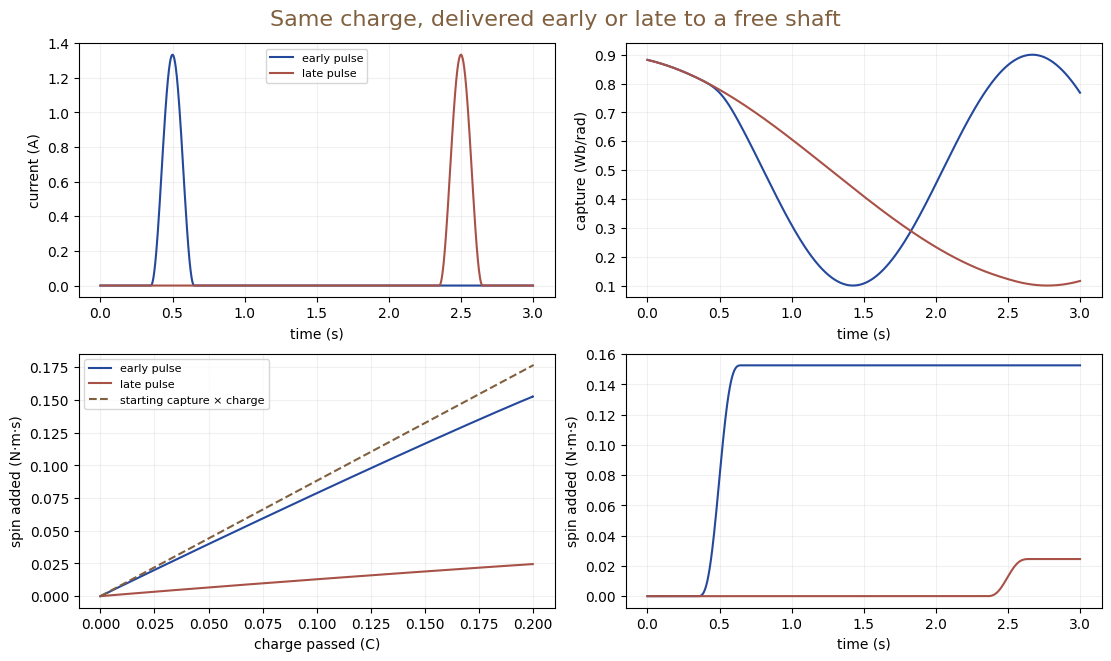

In [5]:
_ = plot_pulses(rippled)

## 3. Let the shaft answer

A bare ring has $\lambda=\lambda_0\cos\theta$ and $\kappa=-\lambda_0\sin\theta$. With a constant positive current, its torque points toward alignment. Add viscous damping and, without an external periodic drive, it settles regularly. **Changing capture alone does not imply chaos.**

Now a separate actuator drives the shaft with a sinusoidal torque:

$$\eta\dot\omega=\kappa(\theta)i+\chi_d\cos(\Omega t)-b\omega.$$

The saved example uses $\eta=1$ kg·m², $i=1$ A, $\lambda_0=1$ Wb, $b=0.5$ N·m·s/rad, $\chi_d=1.2$ N·m, and $\Omega=2/3$ rad/s. A second start differs by only $10^{-8}$ rad. Compare that with a constant-capture shaft under the same external drive.

The ring shows irregular reversals, a spread of once-per-cycle samples, and exponential growth of small perturbations over a finite interval. The notebook computes tangent growth as a separate diagnostic; a scattered picture alone would not establish chaos. The underlying magnetic torque has the same equation as the restoring torque of a driven pendulum. The periodic actuator supplies energy; damping removes it. Capture still gives matching motor power $\chi\omega=\mathcal E i$ at every instant.

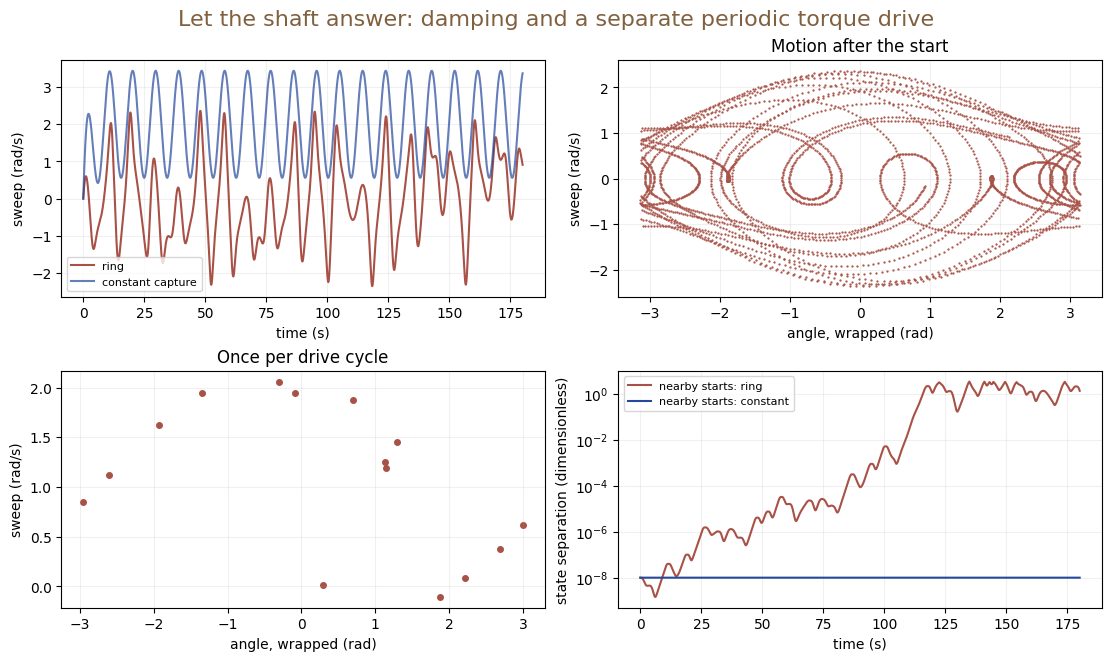

In [6]:
_ = plot_driven(ring)

### Extra digits for comparing methods

Treat the stated problem values as defining inputs valid to the precision needed for this comparison. Normally we would discard everything beyond about the second significant digit. Here, for example, **0.100000000 N·m·s** and **0.099999990 N·m·s** both round to **0.10 N·m·s**: the extra digits let us see the integration improve. They describe agreement within the model, not extra precision in a measurement.

## Numerical methods and checks

The prescribed-motion curves use analytic derivatives. The free-shaft experiments use SciPy's DOP853 integrator with relative tolerance $2\times10^{-10}$. The maximum step during a charge pulse is at most one twelfth of its width, so the solver cannot step over the pulse. The drive experiment also integrates motor work, actuator work, and dissipated heat.

For a bare ring, the potential associated with its fixed-current magnetic torque is $-i\lambda(\theta)$. No energy is created by changing capture. The independent kinetic-energy/work ledger closes in all three coupling models.

The finite-time growth calculation integrates the linearized mechanical equations at fixed drive phase. It reports growth after the first 40 seconds. Refinement checks use two maximum steps and check the sign of the estimate, rather than demanding long chaotic trajectories agree point for point.

In [7]:
for mode in ['constant', 'ripple', 'ring']:
    law = CaptureLaw(mode, base=0.5)
    early, late = (charge_pulse(law, center=t) for t in (0.5, 2.5))
    print(f"{mode:8s} Q: {early['q'][-1]:.10f}, {late['q'][-1]:.10f} C; "
          f"added spin: {early['added_spin'][-1]:+.9f}, {late['added_spin'][-1]:+.9f} N·m·s")
for step in [0.04, 0.02]:
    result = driven(ring, max_step=step)
    print(f"drive max step {step:g} s: growth {result['lyapunov']:.5f}/s; "
          f"energy residual {np.max(np.abs(result['energy_error'])):.2e} J")

constant Q: 0.2000000000, 0.2000000000 C; added spin: +0.100000000, +0.100000000 N·m·s
ripple   Q: 0.2000000000, 0.1999999992 C; added spin: +0.152624195, +0.024550434 N·m·s
ring     Q: 0.2000000000, 0.1999999996 C; added spin: -0.070209386, -0.034580299 N·m·s
drive max step 0.04 s: growth 0.11580/s; energy residual 3.13e-13 J
drive max step 0.02 s: growth 0.11591/s; energy residual 6.54e-13 J


## Try the controls

Start with **Constant capture**, then choose **Rippling capture** or **Bare ring**. The third tab starts with the driven ring. Set its drive torque to zero to watch the same varying capture settle. Unit changes alter the labels and displayed numbers while preserving the SI state. Every slider that carries units follows its panel's selector.

In [8]:
lab = explore_behavior(units=DISPLAY_UNITS)
display(lab)

Interactive panel constructed successfully. Run this cell with a connected Python kernel to use the controls and unit selectors.


## Sources and provenance

- [SciPy solve_ivp documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html): integration method, tolerances, and maximum step.
- [MIT 8.09, Chapter 7: Chaos and Non-Linear Dynamics](https://ocw.mit.edu/courses/8-09-classical-mechanics-iii-fall-2014/a3b977a17091d225ee1870d100c7a308_MIT8_09F14_Chapter_7.pdf): driven and damped pendulum framework.
- Capture, the mapping table, the SI-default/selectable-unit requirement, and the comparison-precision aside were supplied or requested by dr. kraemer in this conversation. The capture table came through Claude. This notebook's models, implementation, and numerical comparisons are by Codex.

**Provenance — append only.** 2026-10-25: Codex created this companion at dr. kraemer's request to show constant-capture shortcuts and their failure when capture changes. The examples distinguish regular variation from a periodically driven chaotic regime. Earlier coiled-ring problem wording is preserved. The new notebook uses the agreed voltage-drop convention; the older Capture notebook retains its explicitly labeled generated-EMF convention.